# 04 - Compare TF-IDF, ATAE-LSTM and DeBERTa on the held-out test set

Predicts the same labeled test rows with all three trained models, scores them with the same metrics, then writes the winner to `best_model.json`, which the app shows in its sidebar. Choose the app's model from this table, not from validation scores or from agreement on unlabeled comments.

**Input:**
- `data/splits/test_split.csv` and `train_split.csv` (notebook 00)
- the trained models from notebooks 01 (TF-IDF), 02 (ATAE-LSTM) and 03 (DeBERTa). A model that is missing is skipped.

**Output (in `results/`):** `model_comparison.csv`, `best_model.json`, and one test-prediction file per model: `tfidf_test_predictions.csv`, `atae_test_predictions.csv`, `deberta_test_predictions.csv`

The main table uses three classes, because the app shows only negative, neutral and positive: `conflict` is counted as `neutral`. Step 5 repeats the scoring with all four classes, so you can see how each model handles `conflict`.

The test rows were never used for training or for choosing a best epoch. Run this once models are final: re-scoring after more tuning turns the test set into a second validation set.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)

from opinion_owl.config import RESULTS_DIR, TEST_SPLIT, TRAIN_SPLIT
from opinion_owl.inference import MODELS, model_is_trained

PREDICTION_FILES = {
    "TF-IDF": RESULTS_DIR / "tfidf_test_predictions.csv",
    "ATAE-LSTM": RESULTS_DIR / "atae_test_predictions.csv",
    "DeBERTa-v3": RESULTS_DIR / "deberta_test_predictions.csv",
}

LABELS = ["negative", "neutral", "positive"]
LABELS_4 = ["negative", "neutral", "positive", "conflict"]
NUMERIC_LABEL_MAP = {0: "negative", 1: "neutral", 2: "positive", 3: "conflict"}

DROP_OVERLAP_ROWS = True    # True: remove test rows that also appear in training (see step 2)

if not TEST_SPLIT.exists():
    raise FileNotFoundError(f"{TEST_SPLIT} not found. Run notebook 00 (prepare data) first.")

## 1. Load the labeled test rows

In [2]:
def pick_column(frame, options, role):
    """Return the first of the possible column names that exists, so slightly different files still work."""
    for name in options:
        if name in frame.columns:
            return name
    raise ValueError(f"No {role} column found. Looked for {options}. Columns: {list(frame.columns)}")


def raw_label(value):
    """Any label spelling or number -> one of the four labels (conflict kept)."""
    if pd.isna(value):
        return None
    try:
        return NUMERIC_LABEL_MAP[int(float(value))]
    except (ValueError, TypeError, KeyError):
        pass
    text = str(value).strip().lower()
    return {"pos": "positive", "neg": "negative", "neu": "neutral"}.get(text, text)


def three_class(label):
    """The app has no conflict class, so conflict counts as neutral."""
    return "neutral" if label == "conflict" else label


def clean_key(series):
    """Lowercased text used to match the same (sentence, aspect) row across files."""
    return series.astype(str).str.strip().str.lower()


test = pd.read_csv(TEST_SPLIT)

TEXT_COL = pick_column(test, ["text", "sentence", "review", "comment"], "text")
ASPECT_COL = pick_column(test, ["aspect_term", "aspect", "term"], "aspect")
LABEL_COL = pick_column(test, ["label", "polarity", "sentiment", "true_polarity"], "label")

test = test.rename(columns={TEXT_COL: "text", ASPECT_COL: "aspect_term", LABEL_COL: "true_raw"})
test["true_raw"] = test["true_raw"].map(raw_label)
test = test.dropna(subset=["text", "aspect_term", "true_raw"])
test = test[test["true_raw"].isin(LABELS_4)].reset_index(drop=True)
test["true_label"] = test["true_raw"].map(three_class)

test["text_key"] = clean_key(test["text"])
test["aspect_key"] = clean_key(test["aspect_term"])
test = test.drop_duplicates(["text_key", "aspect_key"]).reset_index(drop=True)

print("Test rows:", len(test))
print(test["true_raw"].value_counts())

Test rows: 265
true_raw
positive    117
negative     98
neutral      46
conflict      4
Name: count, dtype: int64


## 2. Check for training rows in the test set

In [3]:
# The dataset can contain repeated (sentence, aspect) pairs, so the same pair could land in
# both training and test. A model that memorised it would score unfairly well on it.
if TRAIN_SPLIT.exists():
    train = pd.read_csv(TRAIN_SPLIT)
    train_text = pick_column(train, ["text", "sentence", "review", "comment"], "text")
    train_aspect = pick_column(train, ["aspect_term", "aspect", "term"], "aspect")
    train_keys = set(zip(clean_key(train[train_text]), clean_key(train[train_aspect])))

    test_pairs = list(zip(test["text_key"], test["aspect_key"]))
    in_train = np.array([pair in train_keys for pair in test_pairs])
    print(f"Test pairs that also appear in training: {int(in_train.sum())} of {len(test)}")

    if in_train.any() and DROP_OVERLAP_ROWS:
        test = test[~in_train].reset_index(drop=True)
        print(f"Removed them. Scoring on {len(test)} test rows.")
    elif in_train.any():
        print("WARNING: these rows are kept, so scores are slightly optimistic.")
else:
    print("train_split.csv not found; skipped the overlap check.")

Test pairs that also appear in training: 0 of 265


## 3. Predict the test rows with each model

In [4]:
# The prediction code for all three models lives in src/opinion_owl/inference.py, so this
# notebook and the real-comment notebook (05) always predict the same way.
# Predicted fresh every run, so an old file from an earlier split is never reused.
for model_name, (runner, required_files, source_notebook, _) in MODELS.items():
    output_path = PREDICTION_FILES[model_name]
    if model_is_trained(model_name):
        print(f"Predicting {len(test)} test rows with {model_name}...")
        result = runner(test)
        out = test[["text", "aspect_term"]].join(result[["predicted_polarity", "confidence"]])
        out.to_csv(output_path, index=False)
        print("  saved:", output_path.name)
    else:
        output_path.unlink(missing_ok=True)
        print(f"[skip] {model_name}: model not found. Run {source_notebook} first.")

Predicting 265 test rows with TF-IDF...
  saved: tfidf_test_predictions.csv
Predicting 265 test rows with ATAE-LSTM...
  saved: atae_test_predictions.csv
Predicting 265 test rows with DeBERTa-v3...


c:\Users\ujjwa\anaconda3\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

  saved: deberta_test_predictions.csv


In [5]:
# Line each model's predictions up with the true labels by (sentence, aspect).
aligned = {}

for model_name, path in PREDICTION_FILES.items():
    if not path.exists():
        continue

    pred = pd.read_csv(path)
    pred = pd.DataFrame({
        "text_key": clean_key(pred["text"]),
        "aspect_key": clean_key(pred["aspect_term"]),
        "pred_raw": pred["predicted_polarity"].map(raw_label),
    }).drop_duplicates(["text_key", "aspect_key"])
    pred["pred"] = pred["pred_raw"].map(three_class)

    merged = test[["text_key", "aspect_key", "true_label", "true_raw"]].merge(
        pred, on=["text_key", "aspect_key"], how="left"
    )
    missing = merged["pred"].isna().sum()
    if missing:
        print(f"[warn] {model_name}: {missing} of {len(merged)} test rows have no prediction (dropped)")
    aligned[model_name] = merged.dropna(subset=["pred"]).reset_index(drop=True)

if not aligned:
    raise RuntimeError("No model predictions available to compare.")

print("Models compared:", list(aligned))
print({name: len(frame) for name, frame in aligned.items()})

Models compared: ['TF-IDF', 'ATAE-LSTM', 'DeBERTa-v3']
{'TF-IDF': 265, 'ATAE-LSTM': 265, 'DeBERTa-v3': 265}


## 4. Scores (three classes)

In [6]:
rows = []
for model_name, frame in aligned.items():
    y_true, y_pred = frame["true_label"], frame["pred"]
    _, _, f1_each, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)

    row = {
        "model": model_name,
        "rows_scored": len(frame),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=LABELS, average="weighted", zero_division=0),
    }
    for label, value in zip(LABELS, f1_each):
        row[f"f1_{label}"] = value
    rows.append(row)

comparison = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
comparison.round(4).to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
comparison.round(4)

,model,rows_scored,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,DeBERTa-v3,265,0.9094,0.8988,0.9109,0.9231,0.8440,0.9292
1,TF-IDF,265,0.6906,0.6509,0.6887,0.6911,0.4898,0.7718
2,ATAE-LSTM,265,0.6566,0.6191,0.6614,0.6827,0.4340,0.7407


TF-IDF
              precision    recall  f1-score   support

    negative      0.710     0.673     0.691        98
     neutral      0.500     0.480     0.490        50
    positive      0.750     0.795     0.772       117

    accuracy                          0.691       265
   macro avg      0.653     0.649     0.651       265
weighted avg      0.688     0.691     0.689       265

ATAE-LSTM
              precision    recall  f1-score   support

    negative      0.645     0.724     0.683        98
     neutral      0.411     0.460     0.434        50
    positive      0.808     0.684     0.741       117

    accuracy                          0.657       265
   macro avg      0.621     0.623     0.619       265
weighted avg      0.673     0.657     0.661       265

DeBERTa-v3
              precision    recall  f1-score   support

    negative      0.928     0.918     0.923        98
     neutral      0.780     0.920     0.844        50
    positive      0.963     0.897     0.929    

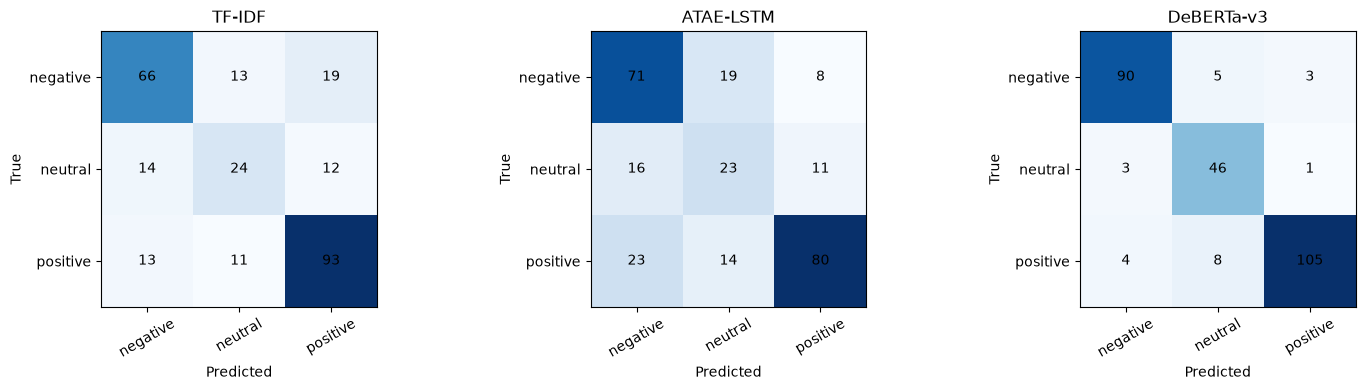

In [7]:
for model_name, frame in aligned.items():
    print("=" * 60)
    print(model_name)
    print(classification_report(frame["true_label"], frame["pred"], labels=LABELS, zero_division=0, digits=3))

fig, axes = plt.subplots(1, len(aligned), figsize=(5 * len(aligned), 4), squeeze=False)
for ax, (model_name, frame) in zip(axes[0], aligned.items()):
    cm = confusion_matrix(frame["true_label"], frame["pred"], labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(model_name)
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS, rotation=30)
    ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

## 5. The same models with all four classes

In [8]:
# The models were trained to predict conflict too. This view keeps it separate, to show how
# each model handles that rare class. It is for information only; the winner is chosen
# on the three-class table.
print("True conflict rows in the test set:", int((test["true_raw"] == "conflict").sum()))

four_class_rows = []
for model_name, frame in aligned.items():
    _, _, f1_each, _ = precision_recall_fscore_support(
        frame["true_raw"], frame["pred_raw"], labels=LABELS_4, zero_division=0
    )
    row = {
        "model": model_name,
        "accuracy_4class": accuracy_score(frame["true_raw"], frame["pred_raw"]),
        "macro_f1_4class": f1_score(frame["true_raw"], frame["pred_raw"], labels=LABELS_4, average="macro", zero_division=0),
    }
    for label, value in zip(LABELS_4, f1_each):
        row[f"f1_{label}"] = value
    row["conflict_predicted"] = int((frame["pred_raw"] == "conflict").sum())
    four_class_rows.append(row)

pd.DataFrame(four_class_rows).sort_values("macro_f1_4class", ascending=False).round(4)

True conflict rows in the test set: 4


,model,accuracy_4class,macro_f1_4class,f1_negative,f1_neutral,f1_positive,f1_conflict,conflict_predicted
2,DeBERTa-v3,0.9057,0.7802,0.9231,0.8687,0.9292,0.4,6
0,TF-IDF,0.6830,0.4893,0.6911,0.4944,0.7718,0.0,5
1,ATAE-LSTM,0.6491,0.4609,0.6827,0.4200,0.7407,0.0,2


## 6. How sure are these scores?

In [9]:
# Bootstrap: re-score 1000 random re-samples of the test rows. The spread shows how much
# the macro-F1 could move by luck on a test set this small. If two models' ranges overlap,
# the test set cannot clearly say which one is better.
rng = np.random.default_rng(42)
N_BOOTSTRAP = 1000

ci_rows = []
for model_name, frame in aligned.items():
    y_true = frame["true_label"].to_numpy()
    y_pred = frame["pred"].to_numpy()
    scores = []
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(frame), len(frame))
        scores.append(f1_score(y_true[idx], y_pred[idx], labels=LABELS, average="macro", zero_division=0))
    low, high = np.percentile(scores, [2.5, 97.5])
    ci_rows.append({"model": model_name, "macro_f1": np.mean(scores), "ci_low": low, "ci_high": high})

pd.DataFrame(ci_rows).sort_values("macro_f1", ascending=False).round(4)

,model,macro_f1,ci_low,ci_high
2,DeBERTa-v3,0.8972,0.8522,0.9361
0,TF-IDF,0.6492,0.5860,0.7101
1,ATAE-LSTM,0.6190,0.5586,0.6765


## 7. Where do the models fail?

In [10]:
# Rows scored by every model, and how many models got each one right.
common = None
for model_name, frame in aligned.items():
    part = frame[["text_key", "aspect_key", "true_label", "pred"]].rename(columns={"pred": model_name})
    common = part if common is None else common.merge(part.drop(columns="true_label"), on=["text_key", "aspect_key"])

model_names = list(aligned)
common["n_correct"] = sum((common[m] == common["true_label"]).astype(int) for m in model_names)

print("Rows scored by every model:", len(common))
print("All correct:", int((common["n_correct"] == len(model_names)).sum()))
print("All wrong:  ", int((common["n_correct"] == 0).sum()))

# Rows every model gets wrong are often label noise rather than model weakness.
hard = common[common["n_correct"] == 0].merge(
    test[["text_key", "aspect_key", "text", "aspect_term"]], on=["text_key", "aspect_key"]
)
hard[["text", "aspect_term", "true_label"] + model_names].head(20)

Rows scored by every model: 265
All correct: 132
All wrong:   8


,text,aspect_term,true_label,TF-IDF,ATAE-LSTM,DeBERTa-v3
0,I also enjoy the fact that my MacBook Pro lapt...,vmware program,neutral,positive,positive,positive
1,That whole experience was just ridiculous we s...,mouse,positive,neutral,negative,negative
2,The macbook rarely requires a hard reboot.,hard reboot,neutral,negative,negative,negative
3,Sure it has the one touch keys but that was th...,one touch keys,positive,neutral,neutral,neutral
4,I know that ASUS is known for making motherboa...,motherboards,neutral,negative,negative,negative
5,I had in the past a Dell laptop and they sent ...,repair technician,positive,neutral,negative,neutral
6,why not tuf? Some rog like zephyrus have worse...,tuf build quality,positive,negative,negative,negative
7,Great present and pretty decent laptop but I h...,windows,negative,positive,positive,positive


In [11]:
per_aspect = []
for model_name, frame in aligned.items():
    merged = frame.merge(test[["text_key", "aspect_key", "aspect_term"]], on=["text_key", "aspect_key"])
    merged["correct"] = merged["true_label"] == merged["pred"]
    grouped = merged.groupby("aspect_term")["correct"].agg(["mean", "count"])
    grouped.columns = [model_name, "n"]
    per_aspect.append(grouped)

aspect_table = pd.concat([per_aspect[0]] + [g.drop(columns="n") for g in per_aspect[1:]], axis=1)
aspect_table = aspect_table[aspect_table["n"] >= 5].sort_values("n", ascending=False)

print("Accuracy by aspect (aspects with at least 5 test rows):")
aspect_table.round(3).head(25)

Accuracy by aspect (aspects with at least 5 test rows):


,TF-IDF,n,ATAE-LSTM,DeBERTa-v3
aspect_term,,,,
use,1.0,6,1.0,1.0
battery life,0.8,5,0.4,1.0
hard drive,0.6,5,0.4,1.0
price,0.8,5,0.8,1.0


## 8. Save the winner for the app

In [12]:
# The app's sidebar reads these four fields (plus rows_scored) from best_model.json.
best = comparison.iloc[0]
summary = {
    "best_model": best["model"],
    "macro_f1": round(float(best["macro_f1"]), 4),
    "accuracy": round(float(best["accuracy"]), 4),
    "rows_scored": int(best["rows_scored"]),
    "selection_rule": "highest macro-F1 on held-out test_split.csv",
}

with open(RESULTS_DIR / "best_model.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "best_model": "DeBERTa-v3",
  "macro_f1": 0.8988,
  "accuracy": 0.9094,
  "rows_scored": 265,
  "selection_rule": "highest macro-F1 on held-out test_split.csv"
}
